# ColumnTransformer and Pipelines


A dataset often needs different preparation for different columns. A `ColumnTransformer` applies those steps by column, and a `Pipeline` connects preprocessing to a model so the same fitted workflow handles training, testing, and future predictions.


<!-- Source transcription: transcription/12.4.md -->
## Transform columns together

Handling every column separately can create several transformed arrays that must be joined in the right order. `ColumnTransformer` applies a named transformer to selected columns and combines the results into one feature matrix.


Each transformer entry has a name, a transformer, and the columns to process. `remainder="passthrough"` keeps unselected columns; `remainder="drop"` removes them.


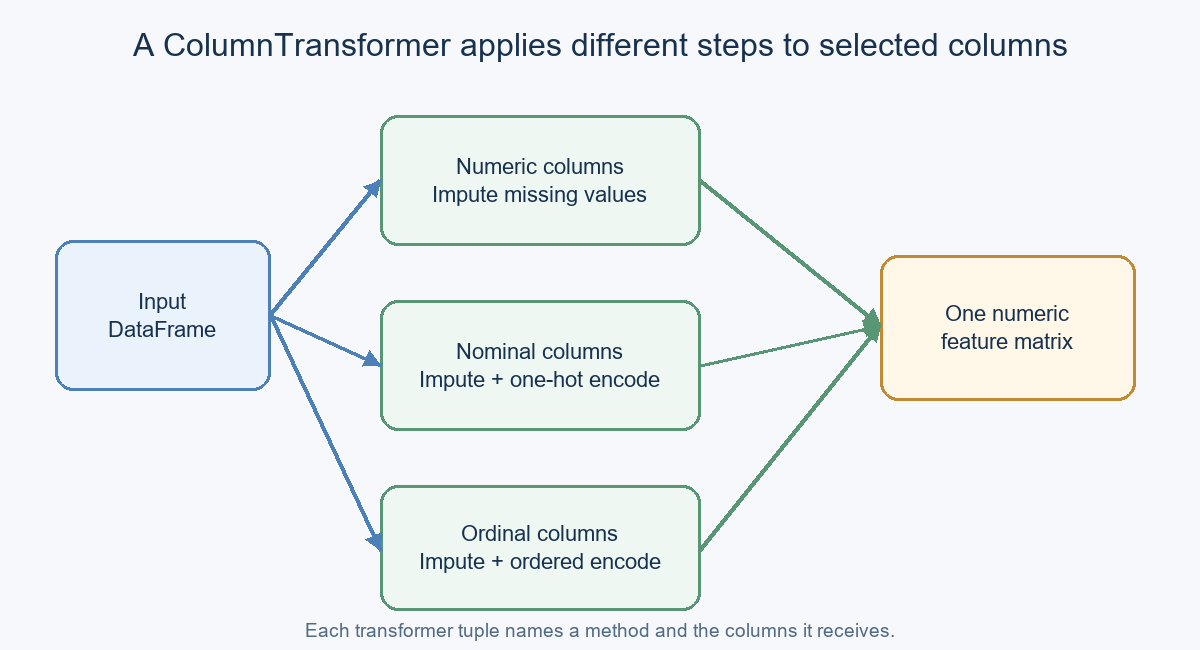

In [1]:
from pathlib import Path
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

covid_path = "/kaggle/input/datasets/nitigyatalwar/covid-toy-datset/covid_toy.csv"
covid = pd.read_csv(covid_path)
X_covid = covid.drop(columns="has_covid")

transformer = ColumnTransformer(
    transformers=[
        ("fever", SimpleImputer(strategy="median"), ["fever"]),
        ("cough", OrdinalEncoder(categories=[["Mild", "Strong"]]), ["cough"]),
        ("nominal", OneHotEncoder(handle_unknown="ignore"), ["gender", "city"]),
    ],
    remainder="passthrough",
)
X_covid_transformed = transformer.fit_transform(X_covid)
print("Input shape:", X_covid.shape)
print("Transformed shape:", X_covid_transformed.shape)
print("Output type:", type(X_covid_transformed).__name__)


Input shape: (100, 5)
Transformed shape: (100, 9)
Output type: ndarray


The separate column operations now produce one matrix. This toy example demonstrates the API; for evaluation, fit transformations on training data only and call `transform()` on validation or test rows.


<!-- Source transcription: transcription/13.1.md -->
## Build a Pipeline

A pipeline chains transformers and a final estimator. The output of each step becomes the next step’s input, which keeps preprocessing consistent between fitting and prediction.


A pipeline is a workflow mechanism, not a learning algorithm. It also prevents preprocessing from being accidentally skipped when a model is used outside the notebook.


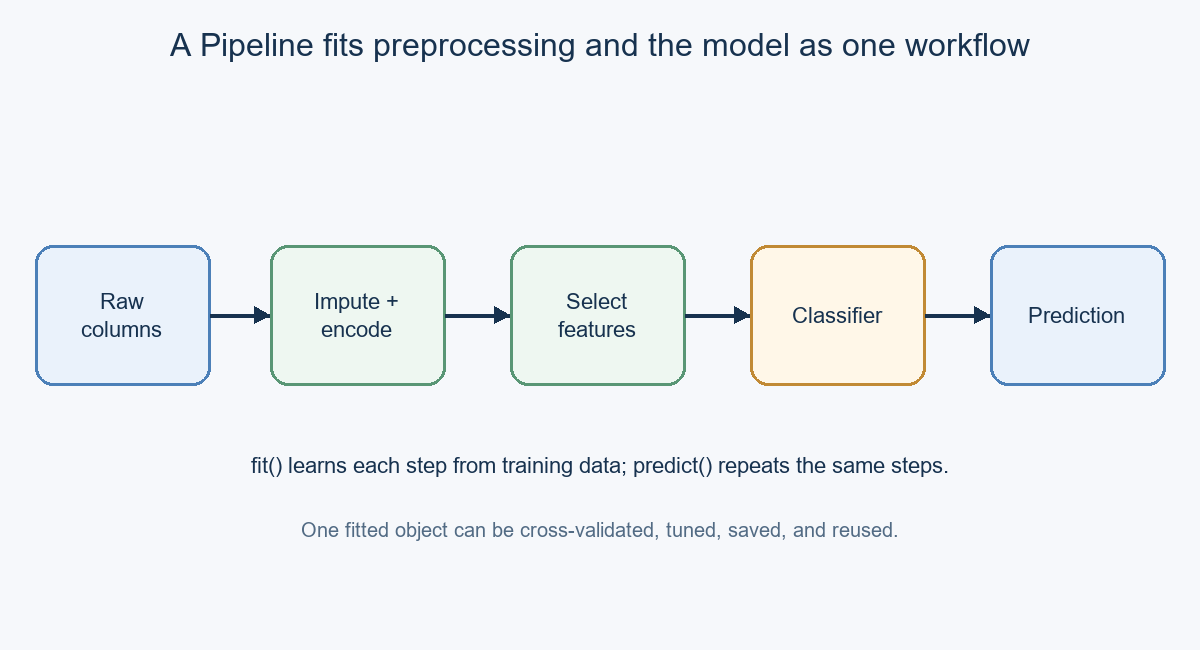

The Day 29 Titanic example first creates separate manual transformations and joins their arrays. We will use the same columns with a `ColumnTransformer` inside a pipeline, which keeps the feature order and fitted encoders together.


In [2]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

titanic_path = "/kaggle/input/datasets/tanadolsrisintron/titanicdataset-traincsv/train.csv"
titanic = pd.read_csv(titanic_path)
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
X = titanic[features]
y = titanic["Survived"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train/test shapes:", X_train.shape, X_test.shape)


Train/test shapes: (712, 7) (179, 7)


The split is made before fitting any preprocessing steps. The holdout set stays separate until we evaluate the completed model.


We will impute missing numeric and categorical values, scale numeric columns to a nonnegative range, encode categories, select features, and fit a decision tree. Min-Max scaling lets the chi-square selector compare nonnegative inputs; decision trees themselves do not need scaling.


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_columns = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_columns = ["Sex", "Embarked"]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ],
    remainder="drop",
)


The numeric and categorical branches can have different steps. `handle_unknown="ignore"` allows prediction when a future row contains a category that was absent during fitting.


In [4]:
pipeline = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("select", SelectKBest(score_func=chi2, k=8)),
    ("model", DecisionTreeClassifier(random_state=42)),
])
pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)
print(f"Holdout accuracy: {accuracy_score(y_test, y_pred):.3f}")


Holdout accuracy: 0.765


The pipeline fits imputers, scaling, encoding, feature selection, and the tree using only the training rows. During prediction it repeats those fitted transformations before producing a class. Accuracy is one measure for this example, not a complete evaluation.


<!-- Source transcription: transcription/13.2.md -->
## Inspect and validate the Pipeline

`Pipeline` asks you to name each step; `make_pipeline` creates names automatically. Named steps make it easier to inspect settings, find fitted values, and address a step during tuning.


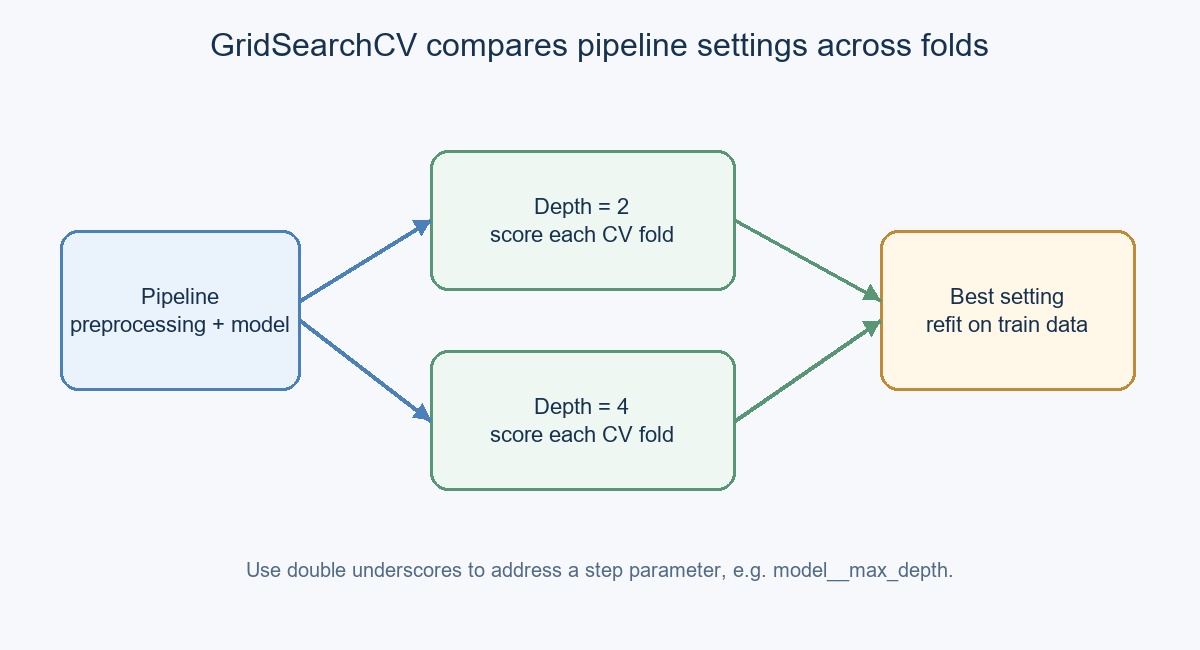

In [5]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(pipeline, X_train, y_train, cv=5, scoring="accuracy")
print("Fold scores:", cv_scores.round(3))
print(f"Mean CV accuracy: {cv_scores.mean():.3f}")
print("Named steps:", list(pipeline.named_steps))


Fold scores: [0.769 0.748 0.796 0.831 0.789]
Mean CV accuracy: 0.787
Named steps: ['preprocess', 'select', 'model']


Cross-validation fits a fresh copy of the full pipeline on each training fold, then scores its validation fold. This keeps each fold’s preprocessing isolated and gives a steadier estimate than one split.


In [6]:
fitted_preprocessor = pipeline.named_steps["preprocess"]
age_imputer = fitted_preprocessor.named_transformers_["numeric"].named_steps["imputer"]
print("Training median values:", age_imputer.statistics_)
print("Output feature names:")
print(fitted_preprocessor.get_feature_names_out())


Training median values: [ 3.     28.5     0.      0.     14.4542]
Output feature names:
['numeric__Pclass' 'numeric__Age' 'numeric__SibSp' 'numeric__Parch'
 'numeric__Fare' 'categorical__Sex_female' 'categorical__Sex_male'
 'categorical__Embarked_C' 'categorical__Embarked_Q'
 'categorical__Embarked_S']


The fitted median values and output names help explain how the transformer handled the training columns. After a `ColumnTransformer`, many steps receive a NumPy or sparse matrix rather than a DataFrame, so column names may no longer be available to later steps.


<!-- Source transcription: transcription/13.3.md -->
## Tune a Pipeline with GridSearchCV

Grid search tries a set of hyperparameter values and compares their cross-validation scores. Use the step name with a double underscore, such as `model__max_depth`, to address a parameter inside a pipeline.


In [7]:
from sklearn.model_selection import GridSearchCV

parameter_grid = {"model__max_depth": [1, 2, 3, 4, 5, None]}
grid = GridSearchCV(
    pipeline, parameter_grid, cv=5, scoring="accuracy", n_jobs=-1
)
grid.fit(X_train, y_train)
print("Best CV accuracy:", round(grid.best_score_, 3))
print("Best parameters:", grid.best_params_)
print("Holdout accuracy:", round(accuracy_score(y_test, grid.predict(X_test)), 3))


Best CV accuracy: 0.798
Best parameters: {'model__max_depth': 3}
Holdout accuracy: 0.788


The search refits the best pipeline on all training rows. The untouched test set gives a final check after tuning; do not choose settings by looking at its score.


## Save and reuse the fitted workflow

A saved pipeline includes the preprocessing and estimator together. In production, load only model files you trust and keep the software versions compatible with the environment that created them.


In [8]:
import pickle
from io import BytesIO

# Demonstrate a local round trip without writing a file.
buffer = BytesIO()
pickle.dump(grid.best_estimator_, buffer)
buffer.seek(0)
loaded_pipeline = pickle.load(buffer)
new_passenger = pd.DataFrame([{
    "Pclass": 2, "Sex": "male", "Age": 31.0, "SibSp": 0,
    "Parch": 0, "Fare": 10.5, "Embarked": "S",
}])
print("Prediction:", loaded_pipeline.predict(new_passenger)[0])


Prediction: 0


The input stays in its original columns and categories; the loaded pipeline applies the same fitted preparation before predicting. That is the main practical benefit of packaging these steps together.
